In [1]:
import signac
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [2]:
mpl.rcParams.update({
    "figure.dpi": 150,
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 1.0,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "errorbar.capsize": 3,
})

In [3]:
class_project = signac.get_project("../signac/dpd_class_workspace/")
xml_project = signac.get_project("../signac/xml_workspace/") # adjust root= if needed

In [4]:
class_data = {}
xml_data = {}

for job in class_project:
    N = job.sp.num_mols * job.sp.lengths  # adjust to your actual state point key for system size
    scores = job.document.get("score", [])
    for entry in scores:
        density, mean_t, std_t, mean_c, std_c, *rest = entry
        success = rest[0] if rest else not (
            np.isnan(mean_t) or mean_t == 0 or mean_c == 0
        )
        if not success:
            continue  # drop any (N, density) set where a run failed
        class_data.setdefault(N, []).append((density, mean_t, std_t, mean_c, std_c))

for job in xml_project:
    N = job.sp.num_mols * job.sp.lengths  # adjust to your actual state point key for system size
    scores = job.document.get("score", [])
    for entry in scores:
        density, mean_t, std_t, mean_c, std_c, *rest = entry
        success = rest[0] if rest else not (
            np.isnan(mean_t) or mean_t == 0 or mean_c == 0
        )
        if not success:
            continue  # drop any (N, density) set where a run failed
        xml_data.setdefault(N, []).append((density, mean_t, std_t, mean_c, std_c))

In [5]:
print(xml_data)

{500: [(0.85, 0.4599772500805557, 0.053789875004440546, 1.002750039100647, 0.0), (1.125, 0.382768583483994, 0.001353124505840242, 1.002750039100647, 0.0), (1.15, 0.3845535625005141, 0.00185135449282825, 0.9922499656677246, 0.0), (1.175, 0.41883914556819946, 0.03540214546956122, 0.9869999885559082, 0.005249977111816406), (1.2, 0.43076437496347353, 0.04825320799136534, 0.9764999747276306, 0.005250036716461182), (1.3, 0.38796068698866293, 0.0015198960318230093, 0.9239999949932098, 0.005250006914138794), (1.4, 0.43076127051608637, 0.026907229505013674, 0.8819999694824219, 0.005249977111816406)], 50: [(0.85, 0.23461695847800002, 0.04342750058276579, 1.002750039100647, 0.0), (1.125, 0.17552156245801598, 0.0003093545092269778, 1.002750039100647, 0.0), (1.15, 0.17066033347509801, 0.0018502085004001856, 0.9922499656677246, 0.0), (1.175, 0.16932945797452703, 0.0007855829899199307, 0.9922499656677246, 0.0), (1.2, 0.1687654999550432, 0.0022555419709533453, 0.9869999885559082, 0.005249977111816406)

In [6]:
for N in class_data:
    class_data[N] = sorted(class_data[N], key=lambda row: row[0])

system_sizes = sorted(class_data.keys())
cmap = plt.get_cmap("viridis")
colors = {N: cmap(i / max(1, len(system_sizes) - 1)) for i, N in enumerate(system_sizes)}
markers = ["o", "s", "^", "D", "v", "P", "X"]

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jr/8265_v612wxg_7hntt0sy_780000gn/T/ipykernel_11535/2176846660.py:28: SyntaxWarning: invalid escape sequence '\s'
  axes[1].set_ylabel("Closest particle distance $(\sigma)$")


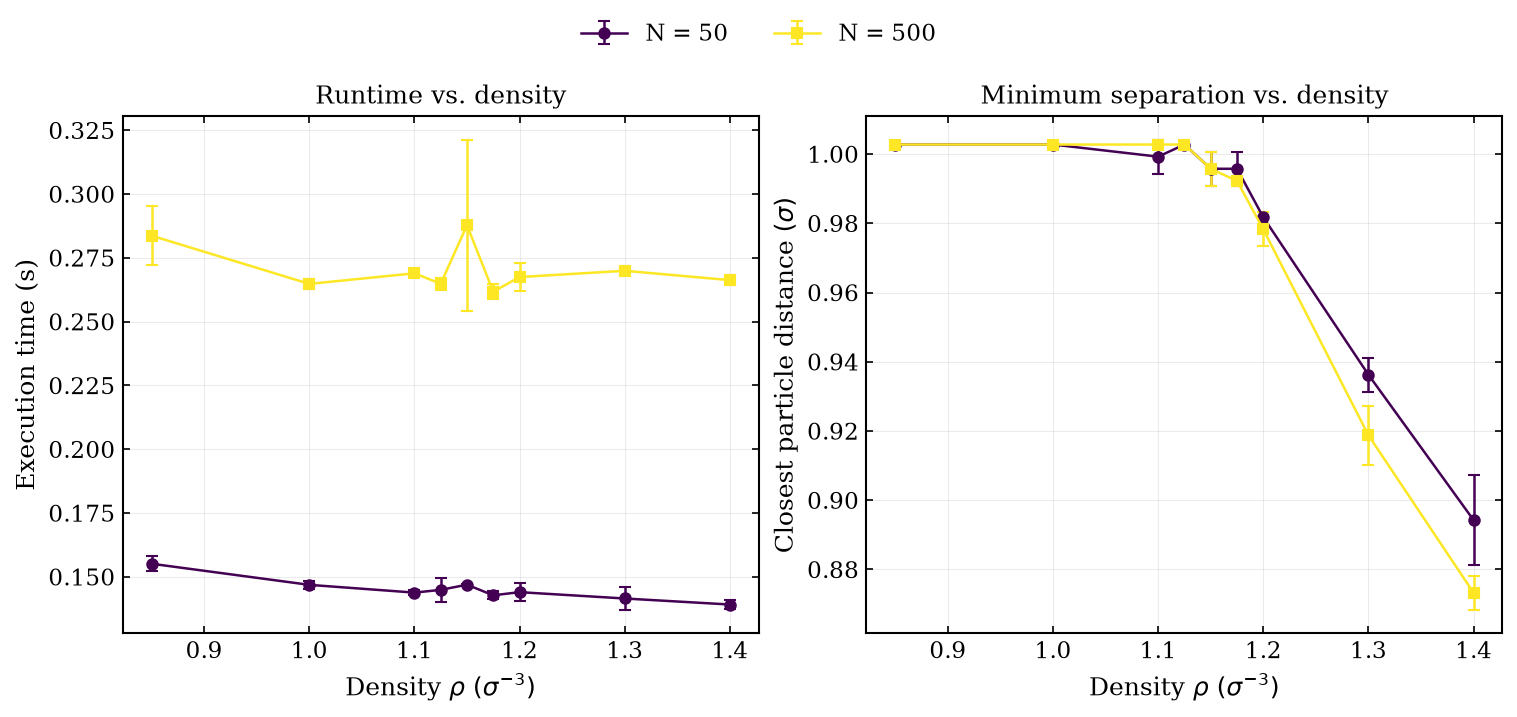

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)

for i, N in enumerate(system_sizes):
    rows = np.array(class_data[N])
    if rows.size == 0:
        continue
    dens, mean_t, std_t, mean_c, std_c = rows.T
    marker = markers[i % len(markers)]

    axes[0].errorbar(
        dens, mean_t, yerr=std_t,
        marker=marker, markersize=5, linestyle="-", linewidth=1.2,
        color=colors[N], ecolor=colors[N], capsize=3,
        label=f"N = {N}",
    )
    axes[1].errorbar(
        dens, mean_c, yerr=std_c,
        marker=marker, markersize=5, linestyle="-", linewidth=1.2,
        color=colors[N], ecolor=colors[N], capsize=3,
        label=f"N = {N}",
    )

axes[0].set_xlabel(r"Density $\rho$ $(\sigma^{-3})$")
axes[0].set_ylabel("Execution time (s)")
axes[0].set_title("Runtime vs. density")

axes[1].set_xlabel(r"Density $\rho$ $(\sigma^{-3})$")
axes[1].set_ylabel("Closest particle distance $(\sigma)$")
axes[1].set_title("Minimum separation vs. density")

# Single shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.12),
           ncol=len(system_sizes), frameon=False)

for ax in axes:
    ax.grid(alpha=0.25, linewidth=0.5)

fig.savefig("sweep_time_and_distance.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
for N in xml_data:
    xml_data[N] = sorted(xml_data[N], key=lambda row: row[0])

system_sizes = sorted(xml_data.keys())
cmap = plt.get_cmap("viridis")
colors = {N: cmap(i / max(1, len(system_sizes) - 1)) for i, N in enumerate(system_sizes)}
markers = ["o", "s", "^", "D", "v", "P", "X"]

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
/var/folders/jr/8265_v612wxg_7hntt0sy_780000gn/T/ipykernel_11535/2407152112.py:28: SyntaxWarning: invalid escape sequence '\s'
  axes[1].set_ylabel("Closest particle distance $(\sigma)$")


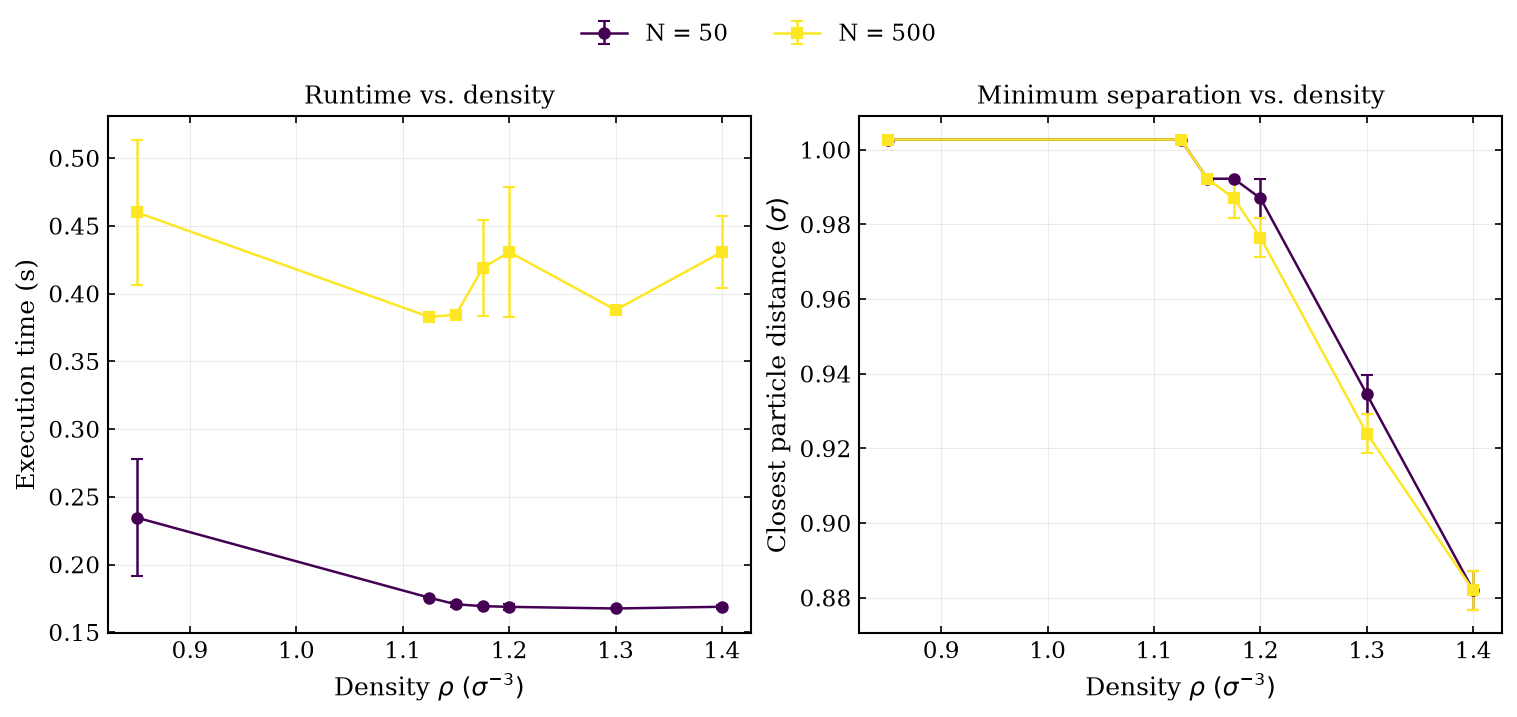

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)

for i, N in enumerate(system_sizes):
    rows = np.array(xml_data[N])
    if rows.size == 0:
        continue
    dens, mean_t, std_t, mean_c, std_c = rows.T
    marker = markers[i % len(markers)]

    axes[0].errorbar(
        dens, mean_t, yerr=std_t,
        marker=marker, markersize=5, linestyle="-", linewidth=1.2,
        color=colors[N], ecolor=colors[N], capsize=3,
        label=f"N = {N}",
    )
    axes[1].errorbar(
        dens, mean_c, yerr=std_c,
        marker=marker, markersize=5, linestyle="-", linewidth=1.2,
        color=colors[N], ecolor=colors[N], capsize=3,
        label=f"N = {N}",
    )

axes[0].set_xlabel(r"Density $\rho$ $(\sigma^{-3})$")
axes[0].set_ylabel("Execution time (s)")
axes[0].set_title("Runtime vs. density")

axes[1].set_xlabel(r"Density $\rho$ $(\sigma^{-3})$")
axes[1].set_ylabel("Closest particle distance $(\sigma)$")
axes[1].set_title("Minimum separation vs. density")

# Single shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.12),
           ncol=len(system_sizes), frameon=False)

for ax in axes:
    ax.grid(alpha=0.25, linewidth=0.5)

fig.savefig("sweep_time_and_distance.png", dpi=300, bbox_inches="tight")
plt.show()